### 1. Importing Libraries

In [2]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


### 2. Creating the Dataset

In [3]:
data = [

    # 1. Symptoms
    ("What are the common symptoms of diabetes?", "symptoms"),
    ("How can I identify early signs of diabetes?", "symptoms"),
    ("Why do diabetic patients feel thirsty frequently?", "symptoms"),
    ("Does diabetes cause frequent urination?", "symptoms"),
    ("Can diabetes cause unexplained weight loss?", "symptoms"),
    ("Why do I feel tired all the time with diabetes?", "symptoms"),
    ("Can blurred vision be a sign of diabetes?", "symptoms"),
    ("What are the warning signs of high blood sugar?", "symptoms"),

    # 2. Causes and Risk Factors
    ("What causes diabetes?", "causes_risk"),
    ("Is diabetes hereditary?", "causes_risk"),
    ("Can obesity increase the risk of diabetes?", "causes_risk"),
    ("Does family history affect diabetes risk?", "causes_risk"),
    ("Can lack of exercise lead to type 2 diabetes?", "causes_risk"),
    ("What are the major risk factors for diabetes?", "causes_risk"),
    ("Does age increase the chances of developing diabetes?", "causes_risk"),
    ("Can unhealthy eating habits contribute to diabetes?", "causes_risk"),

    # 3. Prevention
    ("How can I prevent type 2 diabetes?", "prevention"),
    ("What lifestyle changes help prevent diabetes?", "prevention"),
    ("Does regular exercise reduce diabetes risk?", "prevention"),
    ("How important is maintaining a healthy weight?", "prevention"),
    ("Can walking daily help prevent diabetes?", "prevention"),
    ("What habits should I follow to reduce diabetes risk?", "prevention"),
    ("How can I maintain healthy blood sugar levels?", "prevention"),
    ("Can a balanced diet help prevent diabetes?", "prevention"),

    # 4. Diagnosis and Tests
    ("Which tests are used to diagnose diabetes?", "diagnosis"),
    ("What is a fasting blood sugar test?", "diagnosis"),
    ("What does an HbA1c test measure?", "diagnosis"),
    ("How is diabetes detected?", "diagnosis"),
    ("What is the normal blood glucose range?", "diagnosis"),
    ("How often should blood sugar be tested?", "diagnosis"),
    ("What is an oral glucose tolerance test?", "diagnosis"),
    ("What does a high HbA1c result indicate?", "diagnosis"),

    # 5. Diet and Nutrition
    ("What foods should diabetic patients eat?", "diet"),
    ("Which fruits are suitable for people with diabetes?", "diet"),
    ("Should diabetic patients avoid sugary drinks?", "diet"),
    ("Is brown rice better than white rice for diabetes?", "diet"),
    ("What is a healthy breakfast for a diabetic person?", "diet"),
    ("Can people with diabetes eat bananas?", "diet"),
    ("Why is fibre important in a diabetic diet?", "diet"),
    ("What foods can cause blood sugar spikes?", "diet"),

    # 6. Treatment and Management
    ("How is diabetes treated?", "treatment"),
    ("What is insulin therapy?", "treatment"),
    ("How does metformin help manage diabetes?", "treatment"),
    ("Can type 2 diabetes be managed with lifestyle changes?", "treatment"),
    ("Why do some diabetic patients need insulin injections?", "treatment"),
    ("How can I manage diabetes daily?", "treatment"),
    ("What are the common types of diabetes medication?", "treatment"),
    ("Why is regular blood sugar monitoring important?", "treatment"),

    # 7. Complications
    ("What are the long term complications of diabetes?", "complications"),
    ("Can diabetes affect the kidneys?", "complications"),
    ("How does diabetes affect eyesight?", "complications"),
    ("Can diabetes cause nerve damage?", "complications"),
    ("Does diabetes increase the risk of heart disease?", "complications"),
    ("What is diabetic neuropathy?", "complications"),
    ("Can diabetes affect wound healing?", "complications"),
    ("How can diabetes affect foot health?", "complications"),

    # 8. Emergency
    ("What should I do if someone with diabetes becomes unconscious?", "emergency"),
    ("What are the signs of severe low blood sugar?", "emergency"),
    ("Can diabetic ketoacidosis be life threatening?", "emergency"),
    ("What should I do during a severe hypoglycemic episode?", "emergency"),
    ("What are the warning signs of diabetic ketoacidosis?", "emergency"),
    ("When should a diabetic patient seek emergency medical help?", "emergency"),
    ("What should I do if a diabetic person has a seizure?", "emergency"),
    ("Is severe confusion in a diabetic patient an emergency?", "emergency")
]

df = pd.DataFrame(data, columns=["query", "intent"])

print("Dataset created successfully!")
print("Total queries:", len(df))
print("Total intent categories:", df["intent"].nunique())

df.head(10)

Dataset created successfully!
Total queries: 64
Total intent categories: 8


,query,intent
0,What are the common symptoms of diabetes?,symptoms
1,How can I identify early signs of diabetes?,symptoms
2,Why do diabetic patients feel thirsty frequently?,symptoms
3,Does diabetes cause frequent urination?,symptoms
4,Can diabetes cause unexplained weight loss?,symptoms
5,Why do I feel tired all the time with diabetes?,symptoms
6,Can blurred vision be a sign of diabetes?,symptoms
7,What are the warning signs of high blood sugar?,symptoms
8,What causes diabetes?,causes_risk
9,Is diabetes hereditary?,causes_risk


### 3. Exploring the Dataset

In [4]:
print("Dataset Information:")
df.info()

print("\nIntent Distribution:")
print(df["intent"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Queries:")
print(df["query"].duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   query   64 non-null     object
 1   intent  64 non-null     object
dtypes: object(2)
memory usage: 1.1+ KB

Intent Distribution:
intent
symptoms         8
causes_risk      8
prevention       8
diagnosis        8
diet             8
treatment        8
complications    8
emergency        8
Name: count, dtype: int64

Missing Values:
query     0
intent    0
dtype: int64

Duplicate Queries:
0


### 4. Visualising Intent Distribution

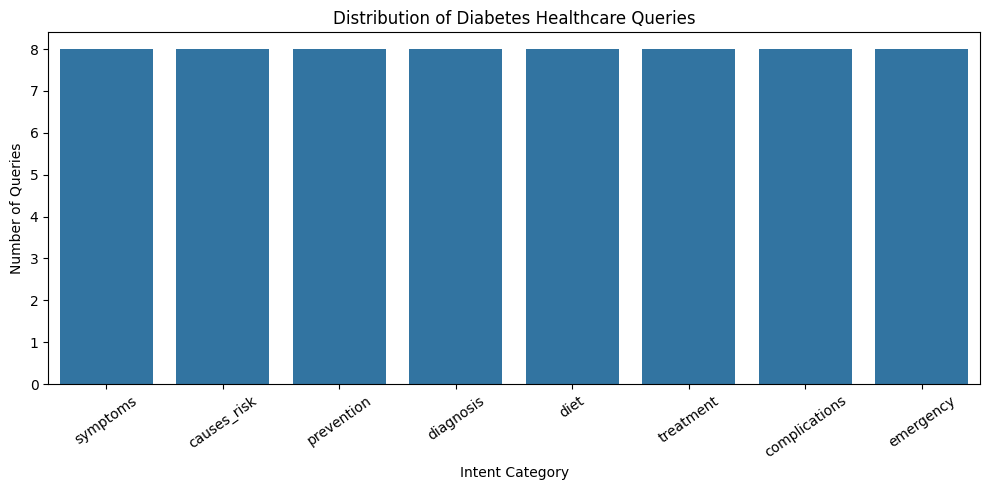

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="intent",
    order=df["intent"].value_counts().index
)

plt.title("Distribution of Diabetes Healthcare Queries")
plt.xlabel("Intent Category")
plt.ylabel("Number of Queries")
plt.xticks(rotation=35)

plt.tight_layout()
plt.show()

### 5. Saving the Dataset

In [6]:
df.to_csv("diabetes_query_dataset.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


### B) 1. Defining the taxonomy

In [7]:
taxonomy = {
    "Diabetes Awareness": {
        "Symptoms": ["symptoms"],
        "Causes and Risk Factors": ["causes_risk"]
    },

    "Prevention and Lifestyle": {
        "Preventive Measures": ["prevention"],
        "Diet and Nutrition": ["diet"]
    },

    "Diagnosis and Management": {
        "Diagnostic Tests": ["diagnosis"],
        "Treatment and Management": ["treatment"]
    },

    "Health Risks and Safety": {
        "Complications": ["complications"],
        "Emergency Conditions": ["emergency"]
    }
}

print("Hierarchical taxonomy created successfully!")

Hierarchical taxonomy created successfully!


### 2. Displaying the taxonomy

In [8]:
for major_category, subcategories in taxonomy.items():

    print("\n" + major_category)

    for subcategory, intents in subcategories.items():
        print("   |--", subcategory, ":", intents)


Diabetes Awareness
   |-- Symptoms : ['symptoms']
   |-- Causes and Risk Factors : ['causes_risk']

Prevention and Lifestyle
   |-- Preventive Measures : ['prevention']
   |-- Diet and Nutrition : ['diet']

Diagnosis and Management
   |-- Diagnostic Tests : ['diagnosis']
   |-- Treatment and Management : ['treatment']

Health Risks and Safety
   |-- Complications : ['complications']
   |-- Emergency Conditions : ['emergency']


### 3. Verifying taxonomy requirements

In [9]:
major_count = len(taxonomy)

subcategory_count = sum(
    len(subcategories)
    for subcategories in taxonomy.values()
)

print("Number of major categories:", major_count)
print("Number of subcategories:", subcategory_count)

assert major_count >= 4
assert all(len(subcategories) >= 2
           for subcategories in taxonomy.values())

print("All taxonomy requirements satisfied!")

Number of major categories: 4
Number of subcategories: 8
All taxonomy requirements satisfied!


### C) 1. Defining domain concepts

In [10]:
domain_concepts = {
    "Diabetes": "A chronic condition affecting blood glucose regulation.",
    "Blood Glucose": "The amount of glucose present in the blood.",
    "Insulin": "A hormone that helps glucose enter body cells.",
    "Pancreas": "An organ that produces insulin.",
    "HbA1c": "A blood test that indicates average blood glucose over approximately three months.",
    "Diet": "Food and nutrition habits that influence blood glucose.",
    "Exercise": "Physical activity that can help improve blood glucose control.",
    "Medication": "Medicines used to manage diabetes.",
    "Diagnosis": "The process of identifying diabetes through medical tests.",
    "Complications": "Health problems that may develop due to diabetes."
}

print("Total domain concepts:", len(domain_concepts))

for concept, description in domain_concepts.items():
    print(f"\n{concept}: {description}")

Total domain concepts: 10

Diabetes: A chronic condition affecting blood glucose regulation.

Blood Glucose: The amount of glucose present in the blood.

Insulin: A hormone that helps glucose enter body cells.

Pancreas: An organ that produces insulin.

HbA1c: A blood test that indicates average blood glucose over approximately three months.

Diet: Food and nutrition habits that influence blood glucose.

Exercise: Physical activity that can help improve blood glucose control.

Medication: Medicines used to manage diabetes.

Diagnosis: The process of identifying diabetes through medical tests.

Complications: Health problems that may develop due to diabetes.


### 2. Defining relationships

In [11]:
relationships = [
    ("Diabetes", "affects", "Blood Glucose"),
    ("Pancreas", "produces", "Insulin"),
    ("Insulin", "regulates", "Blood Glucose"),
    ("Diabetes", "is_assessed_using", "HbA1c"),
    ("Diet", "influences", "Blood Glucose"),
    ("Exercise", "helps_regulate", "Blood Glucose"),
    ("Medication", "helps_manage", "Diabetes"),
    ("Diagnosis", "uses", "HbA1c"),
    ("Diabetes", "may_cause", "Complications"),
    ("Insulin", "is_used_in_treatment_of", "Diabetes"),
    ("Exercise", "supports_management_of", "Diabetes"),
    ("Diet", "supports_management_of", "Diabetes")
]

print("Total relationships:", len(relationships))

for subject, relation, object_ in relationships:
    print(f"{subject} --{relation}--> {object_}")

Total relationships: 12
Diabetes --affects--> Blood Glucose
Pancreas --produces--> Insulin
Insulin --regulates--> Blood Glucose
Diabetes --is_assessed_using--> HbA1c
Diet --influences--> Blood Glucose
Exercise --helps_regulate--> Blood Glucose
Medication --helps_manage--> Diabetes
Diagnosis --uses--> HbA1c
Diabetes --may_cause--> Complications
Insulin --is_used_in_treatment_of--> Diabetes
Exercise --supports_management_of--> Diabetes
Diet --supports_management_of--> Diabetes


### 3. Visualising the domain relationships

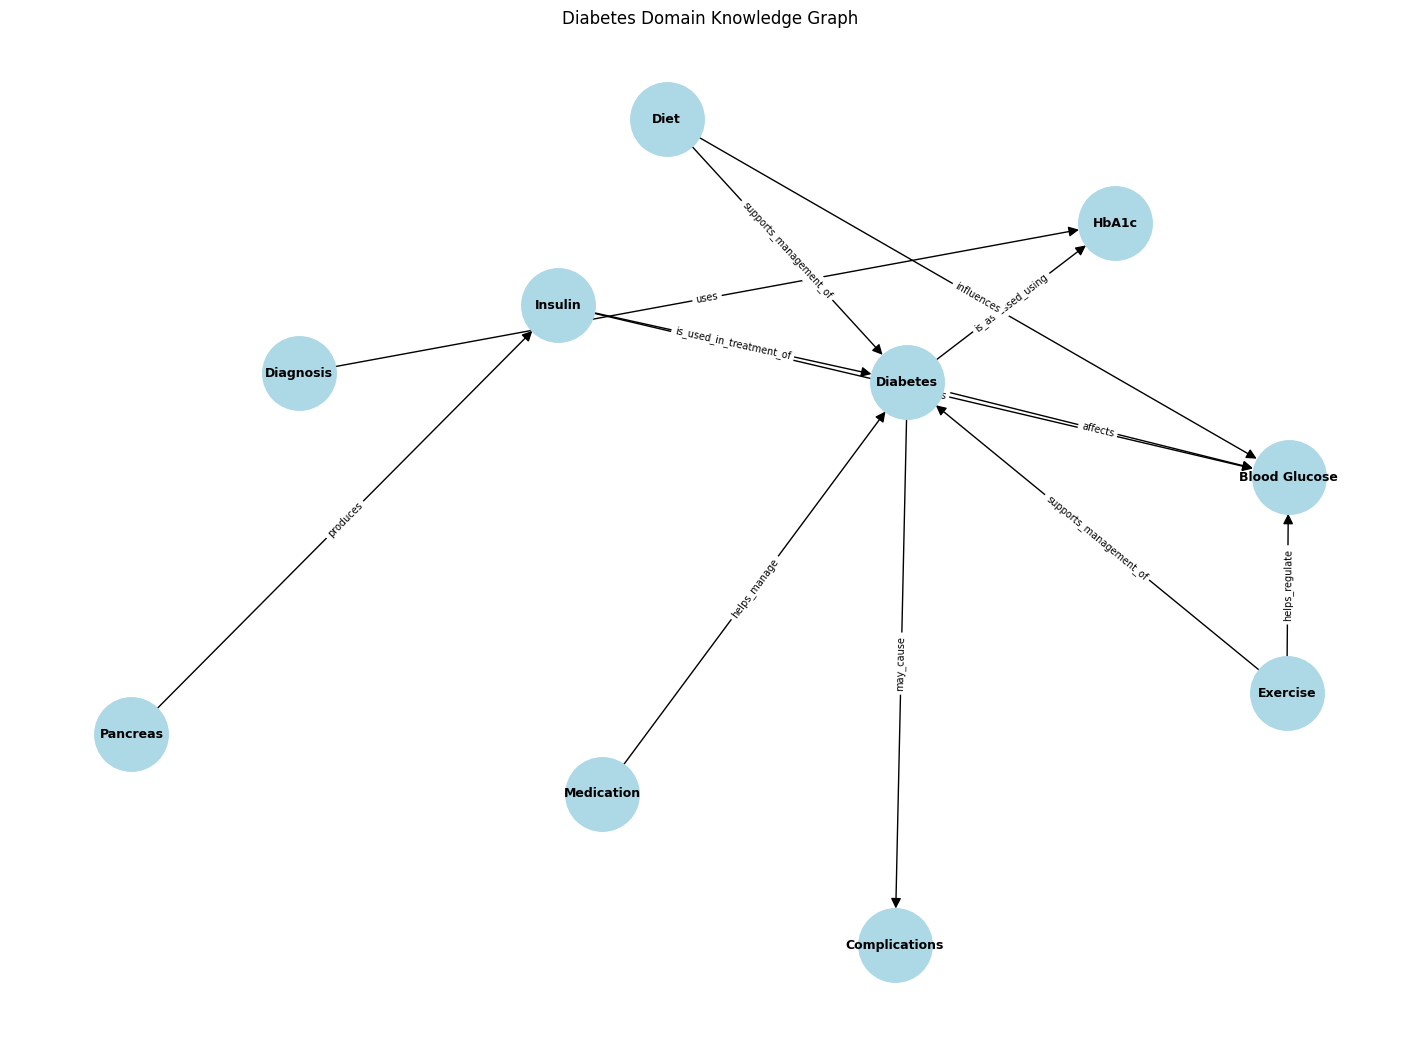

In [12]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

for subject, relation, object_ in relationships:
    G.add_edge(subject, object_, label=relation)

plt.figure(figsize=(14, 10))

pos = nx.spring_layout(G, seed=42, k=1.5)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_color="lightblue",
    node_size=2800,
    font_size=9,
    font_weight="bold",
    arrows=True,
    arrowsize=15
)

edge_labels = nx.get_edge_attributes(G, "label")

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=7
)

plt.title("Diabetes Domain Knowledge Graph")
plt.axis("off")
plt.show()

### 4. Verifying the requirements

In [13]:
print("Number of domain concepts:", len(domain_concepts))
print("Number of relationships:", len(relationships))

assert len(domain_concepts) >= 8
assert len(relationships) >= 10

print("All domain concept and relationship requirements satisfied!")

Number of domain concepts: 10
Number of relationships: 12
All domain concept and relationship requirements satisfied!


### D) NLP Text Preprocessing
### 1. Installing and importing NLTK

In [14]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.


In [15]:
import nltk
import re

from nltk.tokenize import wordpunct_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("NLTK libraries ready!")

NLTK libraries ready!


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\samri\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\samri\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\samri\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


### 2. Initialising preprocessing tools

In [16]:
stop_words = set(stopwords.words('english'))

lemmatizer = WordNetLemmatizer()

print("Stopwords loaded:", len(stop_words))
print("Lemmatizer initialised successfully!")

Stopwords loaded: 198
Lemmatizer initialised successfully!


### 3. Creating the preprocessing function

In [17]:
def preprocess_text(text):

    # Step 1: Convert text to lowercase
    text = text.lower()

    # Step 2: Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', '', text)

    # Step 3: Tokenization
    tokens = wordpunct_tokenize(text)

    # Step 4: Stopword removal
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # Step 5: Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return tokens

### 4. Applying preprocessing to the dataset

In [18]:
df["processed_query"] = df["query"].apply(preprocess_text)

df[["query", "processed_query", "intent"]].head(10)

,query,processed_query,intent
0,What are the common symptoms of diabetes?,"[common, symptom, diabetes]",symptoms
1,How can I identify early signs of diabetes?,"[identify, early, sign, diabetes]",symptoms
2,Why do diabetic patients feel thirsty frequently?,"[diabetic, patient, feel, thirsty, frequently]",symptoms
3,Does diabetes cause frequent urination?,"[diabetes, cause, frequent, urination]",symptoms
4,Can diabetes cause unexplained weight loss?,"[diabetes, cause, unexplained, weight, loss]",symptoms
5,Why do I feel tired all the time with diabetes?,"[feel, tired, time, diabetes]",symptoms
6,Can blurred vision be a sign of diabetes?,"[blurred, vision, sign, diabetes]",symptoms
7,What are the warning signs of high blood sugar?,"[warning, sign, high, blood, sugar]",symptoms
8,What causes diabetes?,"[cause, diabetes]",causes_risk
9,Is diabetes hereditary?,"[diabetes, hereditary]",causes_risk


### 5. Comparing original and processed queries

In [19]:
for i in range(5):

    print("Original Query:")
    print(df["query"][i])

    print("\nProcessed Query:")
    print(df["processed_query"][i])

    print("-" * 60)

Original Query:
What are the common symptoms of diabetes?

Processed Query:
['common', 'symptom', 'diabetes']
------------------------------------------------------------
Original Query:
How can I identify early signs of diabetes?

Processed Query:
['identify', 'early', 'sign', 'diabetes']
------------------------------------------------------------
Original Query:
Why do diabetic patients feel thirsty frequently?

Processed Query:
['diabetic', 'patient', 'feel', 'thirsty', 'frequently']
------------------------------------------------------------
Original Query:
Does diabetes cause frequent urination?

Processed Query:
['diabetes', 'cause', 'frequent', 'urination']
------------------------------------------------------------
Original Query:
Can diabetes cause unexplained weight loss?

Processed Query:
['diabetes', 'cause', 'unexplained', 'weight', 'loss']
------------------------------------------------------------


### 6. Converting processed tokens back to text

In [20]:
df["cleaned_query"] = df["processed_query"].apply(
    lambda tokens: " ".join(tokens)
)

df[["query", "cleaned_query", "intent"]].head()

,query,cleaned_query,intent
0,What are the common symptoms of diabetes?,common symptom diabetes,symptoms
1,How can I identify early signs of diabetes?,identify early sign diabetes,symptoms
2,Why do diabetic patients feel thirsty frequently?,diabetic patient feel thirsty frequently,symptoms
3,Does diabetes cause frequent urination?,diabetes cause frequent urination,symptoms
4,Can diabetes cause unexplained weight loss?,diabetes cause unexplained weight loss,symptoms


### 7. Saving the preprocessed dataset

In [21]:
df.to_csv("diabetes_preprocessed_dataset.csv", index=False)

print("Preprocessed dataset saved successfully!")

Preprocessed dataset saved successfully!


### E) 1. TF-IDF Feature Extraction and Dataset Splitting

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X = df["cleaned_query"]
y = df["intent"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training samples:", X_train_tfidf.shape[0])
print("Testing samples:", X_test_tfidf.shape[0])
print("Total TF-IDF features:", X_train_tfidf.shape[1])

Training samples: 51
Testing samples: 13
Total TF-IDF features: 112


### 2. Visualising TF-IDF Features

In [23]:
feature_names = tfidf.get_feature_names_out()

tfidf_df = pd.DataFrame(
    X_train_tfidf.toarray(),
    columns=feature_names
)

print("First 20 extracted features:")
print(feature_names[:20])

tfidf_df.head()

First 20 extracted features:
['affect' 'avoid' 'banana' 'becomes' 'blood' 'cause' 'change' 'common'
 'complication' 'confusion' 'contribute' 'daily' 'damage' 'diabetes'
 'diabetic' 'diagnose' 'diet' 'disease' 'drink' 'early']


,affect,avoid,banana,becomes,blood,cause,change,common,complication,confusion,...,type,unconscious,unexplained,unhealthy,urination,used,walking,warning,weight,wound
0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
1,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.653143,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
2,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
3,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
4,0.0,0.0,0.0,0.0,0.383511,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.491634,0.0,0.0


### F) 1. Training the Intent Classification Model

In [24]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Intent classification model trained successfully!")

Intent classification model trained successfully!


### 2. Making predictions

In [25]:
y_pred = model.predict(X_test_tfidf)

results = pd.DataFrame({
    "Actual Intent": y_test.values,
    "Predicted Intent": y_pred
})

print("Sample Predictions:")
display(results.head(10))

Sample Predictions:


,Actual Intent,Predicted Intent
0,diagnosis,causes_risk
1,treatment,causes_risk
2,emergency,symptoms
3,diet,emergency
4,prevention,prevention
5,diagnosis,diagnosis
6,treatment,treatment
7,complications,complications
8,emergency,emergency
9,symptoms,symptoms


### G) Evaluating the Intent Classification Model
### 1. Calculating evaluation metrics

In [26]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 53.85 %

Classification Report:
               precision    recall  f1-score   support

  causes_risk       0.25      1.00      0.40         1
complications       1.00      1.00      1.00         1
    diagnosis       1.00      0.50      0.67         2
         diet       0.00      0.00      0.00         2
    emergency       0.50      0.50      0.50         2
   prevention       1.00      1.00      1.00         1
     symptoms       0.50      0.50      0.50         2
    treatment       0.50      0.50      0.50         2

     accuracy                           0.54        13
    macro avg       0.59      0.62      0.57        13
 weighted avg       0.56      0.54      0.52        13



C:\Users\samri\miniconda3\envs\pythonenv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\samri\miniconda3\envs\pythonenv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\samri\miniconda3\envs\pythonenv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is

### 2. Confusion Matrix

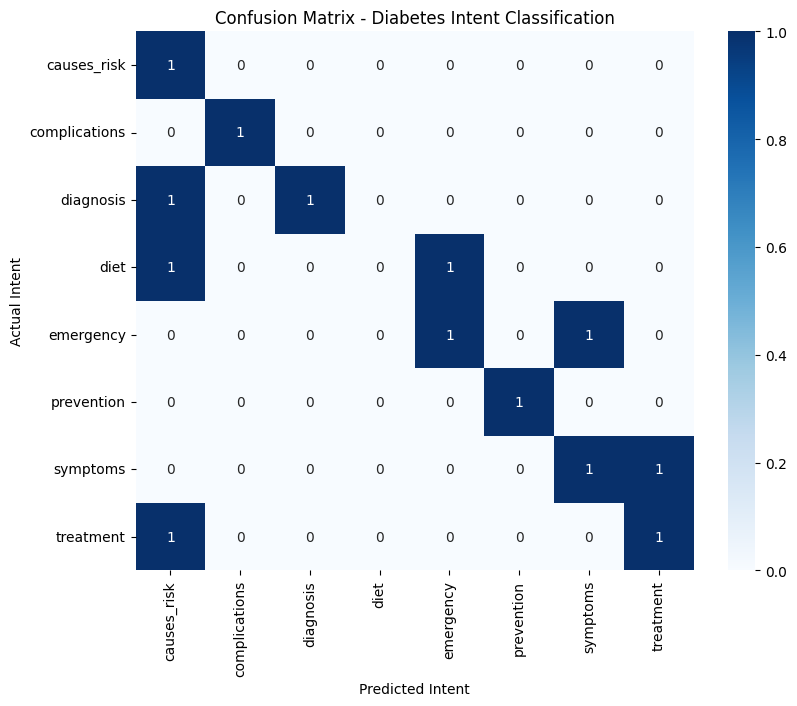

In [27]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.title("Confusion Matrix - Diabetes Intent Classification")
plt.show()

### H)  Developing the Diabetes Healthcare Knowledge Base
### 1. Creating the knowledge base

In [29]:
knowledge_base = {

    "symptoms": """
    Common symptoms of diabetes include frequent urination,
    excessive thirst, increased hunger, fatigue, blurred vision
    and unexplained weight loss.
    """,

    "causes_risk": """
    Risk factors include family history, obesity, physical inactivity,
    increasing age and unhealthy lifestyle habits. Type 1 and
    type 2 diabetes have different underlying causes.
    """,

    "prevention": """
    Type 2 diabetes risk can be reduced through regular physical
    activity, balanced nutrition, maintaining a healthy weight
    and routine health checkups.
    """,

    "diagnosis": """
    Diabetes can be diagnosed using tests such as fasting blood
    glucose, HbA1c and oral glucose tolerance tests. A healthcare
    professional should interpret the results.
    """,

    "diet": """
    A balanced diet containing vegetables, whole grains, fibre
    and appropriate portions can support blood glucose management.
    Individual dietary needs may vary.
    """,

    "treatment": """
    Diabetes management may involve lifestyle changes, regular
    blood glucose monitoring and prescribed medicines such as
    insulin or other glucose-lowering medications.
    """,

    "complications": """
    Diabetes may increase the risk of cardiovascular disease,
    kidney disease, nerve damage, eye problems and foot complications.
    Regular medical monitoring helps reduce risks.
    """,

    "emergency": """
    Severe hypoglycemia, unconsciousness, seizures and symptoms
    of diabetic ketoacidosis require urgent medical attention.
    Contact emergency medical services when these occur.
    """
}

print("Knowledge base created successfully!")
print("Total knowledge categories:", len(knowledge_base))

Knowledge base created successfully!
Total knowledge categories: 8


In [30]:
for intent, information in knowledge_base.items():
    print("\nIntent:", intent)
    print("Information:", information.strip())
    print("-" * 60)


Intent: symptoms
Information: Common symptoms of diabetes include frequent urination,
    excessive thirst, increased hunger, fatigue, blurred vision
    and unexplained weight loss.
------------------------------------------------------------

Intent: causes_risk
Information: Risk factors include family history, obesity, physical inactivity,
    increasing age and unhealthy lifestyle habits. Type 1 and
    type 2 diabetes have different underlying causes.
------------------------------------------------------------

Intent: prevention
Information: Type 2 diabetes risk can be reduced through regular physical
    activity, balanced nutrition, maintaining a healthy weight
    and routine health checkups.
------------------------------------------------------------

Intent: diagnosis
Information: Diabetes can be diagnosed using tests such as fasting blood
    glucose, HbA1c and oral glucose tolerance tests. A healthcare
    professional should interpret the results.
---------------------

### I) Implementing Rule-Based Reasoning
### 1. Defining reasoning rules

In [37]:
import re

def apply_reasoning(query, predicted_intent, confidence):

    query = query.lower()

    # Rule 1: Emergency escalation
    emergency_keywords = [
        "unconscious", "seizure", "severe hypoglycemia",
        "diabetic ketoacidosis", "cannot wake",
        "severe confusion"
    ]

    if any(word in query for word in emergency_keywords):
        return {
            "status": "emergency",
            "response": "EMERGENCY ALERT: Seek immediate medical attention or contact local emergency services."
        }

    # Rule 2: Unsupported queries
    diabetes_keywords = [
        "diabetes", "diabetic", "blood sugar", "glucose",
        "insulin", "hba1c", "hypoglycemia", "hyperglycemia",
        "pancreas", "ketoacidosis", "metformin"
    ]

    if not any(word in query for word in diabetes_keywords):
        return {
            "status": "unsupported",
            "response": "Sorry, I can currently answer questions related to diabetes care only."
        }

    # Rule 3: Low confidence
    if confidence < 0.20:
        return {
            "status": "low_confidence",
            "response": "I'm not confident enough to understand your query. Please rephrase it."
        }

    # Rule 4 and 5: Knowledge retrieval and safety
    if predicted_intent in knowledge_base:
        return {
            "status": "success",
            "response": knowledge_base[predicted_intent] +
            "\n\nNote: This information is educational and not a substitute for professional medical advice."
        }

    return {
        "status": "unsupported",
        "response": "Sorry, I could not find relevant information."
    }

print("Five reasoning rules implemented successfully!")

Five reasoning rules implemented successfully!


### 2. Testing the reasoning rules

In [38]:
test_cases = [
    ("What are diabetes symptoms?", "symptoms", 0.85),
    ("What should I do if a diabetic person becomes unconscious?",
     "emergency", 0.90),
    ("What is diabetes?", "symptoms", 0.20),
    ("How can I book a movie ticket?", "diet", 0.90),
    ("How can I manage my blood sugar?", "prevention", 0.80)
]

for query, intent, confidence in test_cases:

    result = apply_reasoning(query, intent, confidence)

    print("\nQuery:", query)
    print("Status:", result["status"])
    print("Response:", result["response"])
    print("-" * 60)


Query: What are diabetes symptoms?
Status: success
Response: 
    Common symptoms of diabetes include frequent urination,
    excessive thirst, increased hunger, fatigue, blurred vision
    and unexplained weight loss.
    

Note: This information is educational and not a substitute for professional medical advice.
------------------------------------------------------------

Query: What should I do if a diabetic person becomes unconscious?
Status: emergency
Response: EMERGENCY ALERT: Seek immediate medical attention or contact local emergency services.
------------------------------------------------------------

Query: What is diabetes?
Status: success
Response: 
    Common symptoms of diabetes include frequent urination,
    excessive thirst, increased hunger, fatigue, blurred vision
    and unexplained weight loss.
    

Note: This information is educational and not a substitute for professional medical advice.
------------------------------------------------------------

Query: H

### J) Integrating All Components into One Cognitive Assistant
### 1. Creating the integrated assistant

In [49]:
def diabetes_assistant(query):

    # Step 1: Preprocess query
    processed_query = " ".join(preprocess_text(query))

    # Step 2: TF-IDF transformation
    query_vector = tfidf.transform([processed_query])

    # Step 3: Predict intent
    predicted_intent = model.predict(query_vector)[0]

    # Step 4: Calculate confidence
    probabilities = model.predict_proba(query_vector)[0]
    confidence = max(probabilities)

    # Step 5: Keyword-based correction
    query_lower = query.lower()

    if any(word in query_lower for word in ["symptom", "signs", "feel"]):
        predicted_intent = "symptoms"

    elif any(word in query_lower for word in ["food", "eat", "diet", "fruit", "vegetable"]):
        predicted_intent = "diet"

    elif any(word in query_lower for word in ["diagnos", "test", "hba1c"]):
        predicted_intent = "diagnosis"

    elif any(word in query_lower for word in ["complication", "kidney", "nerve damage"]):
        predicted_intent = "complications"

    elif any(word in query_lower for word in ["prevent", "avoid", "exercise"]):
        predicted_intent = "prevention"

    # Step 6: Apply reasoning rules
    result = apply_reasoning(query, predicted_intent, confidence)

    return {
        "query": query,
        "predicted_intent": predicted_intent,
        "confidence": round(float(confidence) * 100, 2),
        "status": result["status"],
        "response": result["response"]
    }

print("Diabetes Cognitive Assistant integrated successfully!")

Diabetes Cognitive Assistant integrated successfully!


### 2. Testing the integrated assistant

In [40]:
user_queries = [
    "What are the symptoms of diabetes?",
    "Which foods are good for diabetic patients?",
    "How is diabetes diagnosed?",
    "What should I do if someone with diabetes becomes unconscious?",
    "How can I book a movie ticket?"
]

for query in user_queries:

    result = diabetes_assistant(query)

    print("\nUser:", result["query"])
    print("Predicted Intent:", result["predicted_intent"])
    print("Confidence:", result["confidence"], "%")
    print("Status:", result["status"])
    print("Assistant:", result["response"])
    print("-" * 65)


User: What are the symptoms of diabetes?
Predicted Intent: causes_risk
Confidence: 22.93 %
Status: success
Assistant: 
    Risk factors include family history, obesity, physical inactivity,
    increasing age and unhealthy lifestyle habits. Type 1 and
    type 2 diabetes have different underlying causes.
    

Note: This information is educational and not a substitute for professional medical advice.
-----------------------------------------------------------------

User: Which foods are good for diabetic patients?
Predicted Intent: diet
Confidence: 27.09 %
Status: success
Assistant: 
    A balanced diet containing vegetables, whole grains, fibre
    and appropriate portions can support blood glucose management.
    Individual dietary needs may vary.
    

Note: This information is educational and not a substitute for professional medical advice.
-----------------------------------------------------------------

User: How is diabetes diagnosed?
Predicted Intent: causes_risk
Confidence

### Deploying the Diabetes Care Assistant Using Gradio

In [46]:
%pip install gradio

  Using cached gradio-6.32.0-py3-none-any.whl.metadata (16 kB)
  Using cached brotli-1.2.1-cp310-cp310-win_amd64.whl.metadata (6.3 kB)
  Using cached fastapi-0.162.5-py3-none-any.whl.metadata (27 kB)
  Using cached gradio_client-2.7.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached groovy-0.1.2-py3-none-any.whl.metadata (6.1 kB)
  Using cached hf_gradio-0.4.1-py3-none-any.whl.metadata (428 bytes)
  Using cached huggingface_hub-2.4.0-py3-none-any.whl.metadata (16 kB)
  Using cached orjson-3.13.0-cp310-cp310-win_amd64.whl.metadata (43 kB)
  Using cached pydantic-2.14.4-py3-none-any.whl.metadata (143 kB)
  Using cached pydub-0.25.1-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached python_multipart-0.0.32-py3-none-any.whl.metadata (2.1 kB)
  Using cached safehttpx-0.1.7-py3-none-any.whl.metadata (4.2 kB)
  Using cached semantic_version-2.10.0-py2.py3-none-any.whl.metadata (9.7 kB)
  Using cached starlette-1.7.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached tomlkit-0.14.0-py3-none

In [50]:
import gradio as gr

def chat_with_assistant(query):

    if not query.strip():
        return "Please enter a healthcare query."

    result = diabetes_assistant(query)

    return (
        f"Predicted Intent: {result['predicted_intent']}\n"
        f"Confidence: {result['confidence']}%\n"
        f"Status: {result['status']}\n\n"
        f"Assistant Response:\n{result['response']}"
    )


demo = gr.Interface(
    fn=chat_with_assistant,
    inputs=gr.Textbox(
        lines=3,
        placeholder="Ask me anything about diabetes care..."
    ),
    outputs=gr.Textbox(
        label="Assistant Response",
        lines=8
    ),
    title="Diabetes Care Information Assistant",
    description=(
        "An NLP-based cognitive assistant that understands "
        "diabetes-related queries and retrieves relevant information."
    ),
    examples=[
        "What are the symptoms of diabetes?",
        "Which foods are good for diabetic patients?",
        "How is diabetes diagnosed?",
        "What are the complications of diabetes?",
        "What is insulin therapy?"
    ]
)

demo.launch(share=True)

* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://eede8030c7b5f187d5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
